Simple Linear Regression

use scikit-learn to implement simple linear regression
create, train & test a linear model on real data

Step 1 - pip install and import all the required lib for simple linear regression

In [1]:
#import all the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#A magical command that display the plot in the notebook itself
%matplotlib inline 

Step 2 - Load the data directly by using pandas lib

In [2]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%202/data/FuelConsumptionCo2.csv"
df = pd.read_csv(url)
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


Step 3 - required data is loaded! now understand the data that us in FuelConsumptionCo2.csv for your task

Task - create a simple linear regression from one if these features to predict CO2 emission of unobserved cars based on that feature

In [4]:
#print the statistical description of the data to understand the data better
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


Apply these rules to clean the data for a simple linear regression task:
----------------------------------------------------------------
1. Understand Your Variables and Task
----------------------------------------------------------------
Rule 1: Define Your Target and Feature
Before any cleaning, you must decide which variable you are trying to predict (the Dependent Variable, or Target, Y) and which variable you will use to predict it (the Independent Variable, or Feature, X).
Task Assumption: In vehicle datasets, the goal is often to predict CO2EMISSIONS.
Example Target (Y): CO2EMISSIONS
Example Feature (X): FUELCONSUMPTION_COMB (Combined fuel consumption)

Rule 2: Check for Irrelevant/Constant Variables
Examine columns with no variation, as they provide no predictive power.
Action: Look at the std (standard deviation) and min/max values.
Observation: MODELYEAR has a standard deviation of 0.0 and all its quartiles are 2014.0.
Cleaning Step: Remove MODELYEAR from your analysis, as it is a constant and adds no value to a regression model.
----------------------------------------------------------------------
2. Check for Data Integrity and Outliers
----------------------------------------------------------------------
Rule 3: Look for Zeroes and Negative Values
Ensure that all numerical values make physical sense for the context. For characteristics like engine size, cylinders, and consumption, values should be non-negative.
Action: Check the min row for columns like ENGINESIZE, CYLINDERS, and all FUELCONSUMPTION columns.
Observation: All min values are non-negative, which is a good sign. For instance, the minimum ENGINESIZE is 1.0 and minimum CYLINDERS is 3.0.

Rule 4: Identify Potential Outliers using Quartiles
Outliers can severely skew the results of a simple linear regression model.
Action: Compare the max value to the 75th percentile (75%). A very large gap might indicate an outlier.
Example: CO2EMISSIONS
75th Percentile: 294.00 and Max: 488.00
Interpretation: The max value is significantly higher than the 75th percentile, suggesting some vehicles emit much higher CO2 than the majority. Flag these for further inspection as this is a dependent variable 

Example: FUELCONSUMPTION_CITY
75th Percentile: 15.55 and Max: 30.20
Cleaning Step: You might decide to winsorize (cap) or remove extreme outliers, especially if they are measurement errors.

Rule 5: Verify Data Types and Units
Ensure columns are in the correct format for modeling.
Action: Note the unit for each variable.
Observation: FUELCONSUMPTION_COMB_MPG is in miles per gallon, while the others are likely in Litres per 100km (L/100km) based on typical vehicle datasets.
Cleaning Step: If your target (Y) is related to fuel use, and your feature (X) is a fuel consumption variable, ensure both use the same units, or one of them is the standard unit for your region. For a simple linear regression, it's generally best to choose only one highly correlated feature, like FUELCONSUMPTION_COMB, and exclude the MPG version to avoid redundancy and potential issues in later tasks like multiple regression.
---------------------------------------------------------------------------
3. Prepare for Linear Regression
---------------------------------------------------------------------------
Rule 6: Check for Distribution and Transformation Needs
While simple linear regression does not strictly require normally distributed variables, heavily skewed data can sometimes benefit from a transformation (like log or square root) to improve the linearity of the relationship.
Action: Compare the mean to the 50% (median) value.
Observation:
For CO2EMISSIONS: Mean (256.23) is slightly higher than the Median (251.00). This suggests a slight right skew (a longer tail towards higher values), which is consistent with the max being far from the 75th percentile.
For CYLINDERS: Mean (5.79) is significantly lower than the Median (6.00). This isn't a continuous variable, so this is just a sign that 4 and 6 cylinder engines are very common, but it's important to treat it as a categorical/ordinal variable in more complex models. For simple regression, you can treat it as a numeric feature for now.
Cleaning Step: If the linear relationship between your chosen X and Y is weak, consider applying a log transformation to Y (e.g., ln(CO2EMISSIONS)) to normalize its distribution and potentially improve linearity.

Rule 7: Handle Missing Values (Not Shown, But Crucial)
Although the count row shows 1067.0 for every column (suggesting no missing data in this view), you should always verify with a full data inspection.
Action: If you had a column with a count less than 1067.0 (the total count), you would have missing data.
Cleaning Step: For simple linear regression, the best approach for missing data (if it were present) is often row-wise deletion (dropping rows with missing values) if the dataset is large enough and the missing data is random.

drop all the irrelavent fields and keep only the required once

In [6]:
cdf = df[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
cdf.head()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244


In [7]:
cdf.describe()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
count,1067.000000,1067.000000,1067.000000,1067.000000
mean,3.346298,5.794752,11.580881,256.228679
std,1.415895,1.797447,3.485595,63.372304
min,1.000000,3.000000,4.700000,108.000000
25%,2.000000,4.000000,9.000000,207.000000
50%,3.400000,6.000000,10.900000,251.000000
75%,4.300000,8.000000,13.350000,294.000000
max,8.400000,12.000000,25.800000,488.000000


Now you've data to run a linear regression! So, find out its visual representation

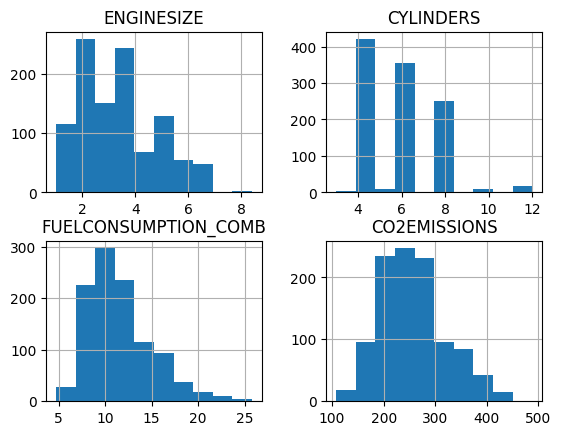

In [8]:
vis = cdf[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
vis.hist() #create histograms of each variable
plt.show() #show the plot inline

most the engineSize is in between 2 to 4 where cylinders are in between 4,6 and 8
FuelConsumption_Comb and CO2Emission have similar destributions 
so, find out the linear relationships between FuelConsumption_Comb and CO2Emission by displaying some scatter plots

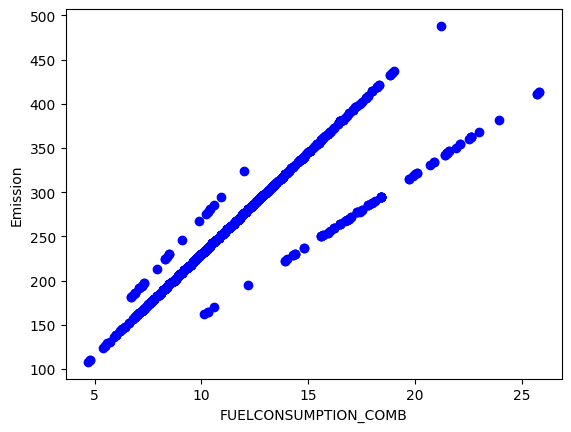

In [13]:
plt.scatter(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("FUELCONSUMPTION_COMB")
plt.ylabel("Emission")
plt.show()

Primary Goal of lineat regression scatter plot is to show the nature of the relationship between X & Y
-- The graph demonstrates that Combined Fuel Consumption is a highly reliable predictor of CO2Emissions.
Analyzing the data distribution
-- Primary Cluster - where the majority of data points a located! primarily ranging from FUELCONSUMPTION_COMB is 5 to 18 & Emission is 120 to 400
-- outlier points - Higer and Lower here! 

repeat the same scattered plot for remaining two columns 'ENGINESIZE','CO2Emissions'

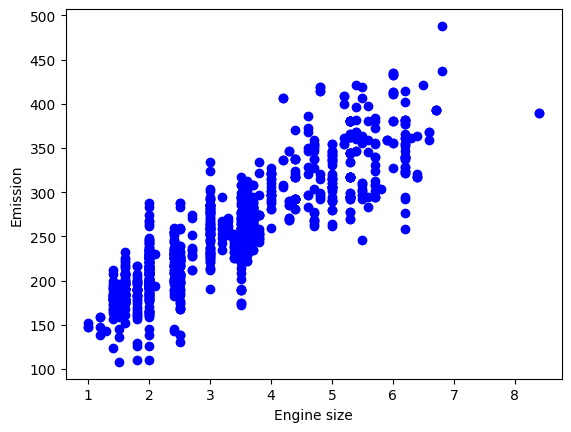

In [15]:
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.show()

Larger engines tend to produce more CO2emissions, but engine size is a less reliable single predictor than combined fuel consumption was.

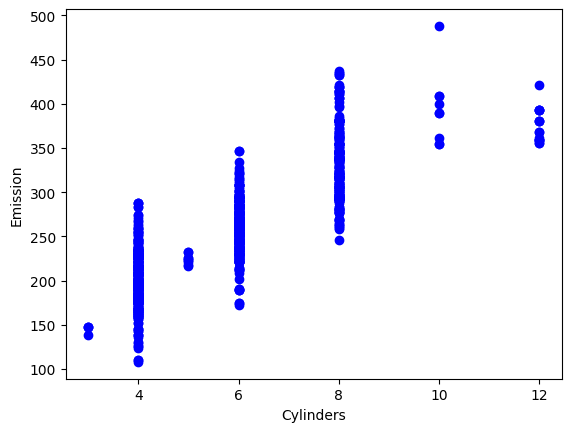

In [16]:
plt.scatter(cdf.CYLINDERS, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("Cylinders")
plt.ylabel("Emission")
plt.show()

Because the x-variable (Cylinders) only takes on a few specific integer values, the data appears in distinct vertical clusters, one for each cylinder count (3, 4, 5, 6, 8, 10, 12).
The average emissions are highest, clustering well above 300.
This confirms the initial finding: more cylinders mean higher average CO2emissions. However, cylinder is not the best choice to use as independent variable

After reviewing all the above graphs, exact the independent variable columns and dependent variable columns! 

In [20]:
X = cdf.ENGINESIZE.to_numpy()
y = cdf.CO2EMISSIONS.to_numpy()

MODELING

Create train & test datasets 


In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
type(X_train), np.shape(X_train), np.shape(X_train)

(numpy.ndarray, (853,), (853,))

In [24]:
type(X_test), np.shape(X_test), np.shape(X_test)

(numpy.ndarray, (214,), (214,))

Build a simple linear regression model
These two printed values complete your simple linear regression equation:
Y=β0+β1X
Emission=Intercept+Coefficient×Feature

In [27]:
from sklearn import linear_model
regr = linear_model.LinearRegression() #This creates an instance (an object) of the Linear Regression model. This object is now ready to be trained

# train the model on the training data
# X_train is a 1-D array but sklearn models expect a 2D array as input for the training data, with shape (n_observations, n_features).
# So we need to reshape it. We can let it infer the number of observations using '-1'.
train_x = X_train.reshape(-1,1)
train_y = y_train.reshape(-1,1)
regr.fit(train_x, train_y)

# The coefficients
#regr.coef_: This prints the coefficient (slope), typically represented as m or β1.
# This value tells you how much the dependent variable (Y, Emission) is expected to change for every one-unit increase in the independent variable (X, e.g., Fuel Consumption).
#regr.intercept_: This prints the intercept, represented as b or β0. 
# This is the predicted value of the dependent variable (Y) when the independent variable (X) is zero.
print('Coefficients: ', regr.coef_)
print('Intercept: ',regr.intercept_)

Coefficients:  [[38.99297872]]
Intercept:  [126.28970217]


Sample, what would be be CO2Emission if EngineeSize in 8
Y(target) = Intercept + Coefficients * X(independent) 

Example:
CO2Emission = 126.289 + 38.99 * 8
CO2Emission = 438.209

regression model is the line given by Y(target) = Intercept + Coefficients * X(independent) 

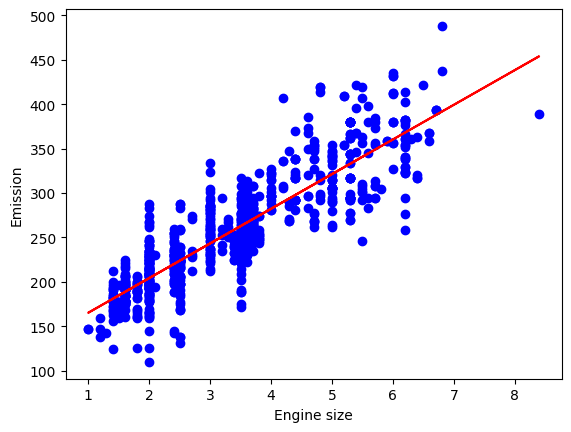

In [ ]:
plt.scatter(X_train, y_train,  color='blue')
plt.plot(X_train, (regr.coef_[0][0] * X_train) + regr.intercept_, '-r') #y=mx+b
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.show()

now, use FUELCOMSUMPTION_COMB and CO2Emission for linear regression

In [31]:
fuelCom_comb = cdf.FUELCONSUMPTION_COMB.to_numpy()
fuelCom_co2Emission = cdf.CO2EMISSIONS.to_numpy()

MODELING

Create a train & test dataset using fuel consumption comb and co2emission

In [32]:
from sklearn.model_selection import train_test_split
fuelComb_train, fuelComb_test, fuel_co2Emission_train, fuel_co2Emission_test = train_test_split(fuelCom_comb, fuelCom_co2Emission, test_size=0.2, random_state=42)
type(fuelComb_train), np.shape(fuelComb_train), np.shape(fuel_co2Emission_train)

(numpy.ndarray, (853,), (853,))

In [33]:
#Build a simple linear regression model
from sklearn import linear_model
regr_fuleCom = linear_model.LinearRegression() #This creates an instance (an object) of the Linear Regression model. This object is now ready to be trained
# train the model on the training data
regr_fuleCom.fit(fuelComb_train.reshape(-1,1), fuel_co2Emission_train.reshape(-1,1))
# The coefficients
print('Coefficients: ', regr_fuleCom.coef_)
print('Intercept: ',regr_fuleCom.intercept_)

Coefficients:  [[16.18090078]]
Intercept:  [69.10302618]


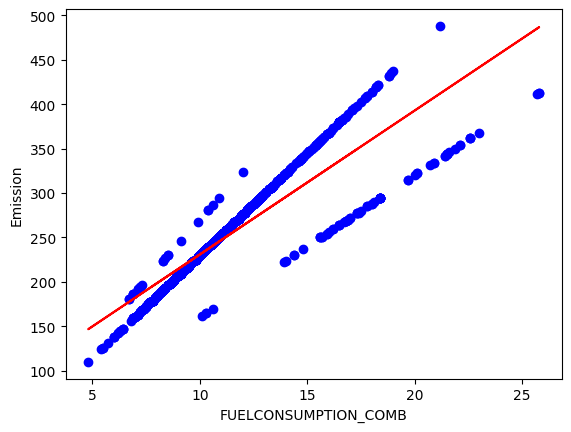

In [34]:
# y = mx + b
# y = CO2Emission
# m = Coefficients
# x = FUELCONSUMPTION_COMB
# b = Intercept
plt.scatter(fuelComb_train, fuel_co2Emission_train,  color='blue')
plt.plot(fuelComb_train, (regr_fuleCom.coef_[0][0] * fuelComb_train) + regr_fuleCom.intercept_, '-r') #y=mx+b
plt.xlabel("FUELCONSUMPTION_COMB")
plt.ylabel("Emission")
plt.show()

Sample, what would be be CO2Emission if Fuel comb in 24
Y(target) = Intercept + Coefficients * X(independent) 

Example:
CO2Emission = 69.10302618 + 16.18090078 * 24
CO2Emission = 437.44

regression model is the line given by Y(target) = Intercept + Coefficients * X(independent) 

Model Evaluation ! 
the purpose of model evalutation is to find out the accuracy of a regression model
There are different model evaluation metrics. 
Model Evaluation Checklist
Checkpoint	Metric/Test	Purpose
1. Goodness of Fit - R2Score - Measures the proportion of the variance in Y that is explained by X. Higher is better (closer to 1.0).
2. Prediction Accuracy - Mean Absolute Error (MAE) - Measures the average magnitude of the errors in a set of predictions. Easy to interpret (same units as Y).
3. Penalty for Errors - Mean Squared Error (MSE) / RMSE - Measures the average squared magnitude of the errors. Higher penalty for large errors. RMSE is often preferred as it's in Y's units.
4. Residual Distribution - Residual Plot / Histogram - Checks the model's assumptions: Is the error term ϵ (residuals) normally distributed? Are there patterns in the error?
5. Linearity Assumption - Residual Plot - Checks for nonlinearity, which would show a distinct curve or pattern in the residuals (e.g., a smile or frown).


In [35]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, explained_variance_score, max_error
y_test_pred = regr.predict(X_test.reshape(-1,1))

print("Mean absolute error: %.2f" % mean_absolute_error(y_test, y_test_pred))
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_test_pred))
print("R2 score: %.2f" % r2_score(y_test, y_test_pred))
print("Explained variance score: %.2f" % explained_variance_score(y_test, y_test_pred))
print("Max error: %.2f" % max_error(y_test, y_test_pred))

Mean absolute error: 24.10
Mean squared error: 985.94
R2 score: 0.76
Explained variance score: 0.76
Max error: 116.94


In [36]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, explained_variance_score, max_error
fuel_co2Emission_test_pred = regr_fuleCom.predict(fuelComb_test.reshape(-1,1))
print("Mean absolute error: %.2f" % mean_absolute_error(fuel_co2Emission_test, fuel_co2Emission_test_pred))
print("Mean squared error: %.2f" % mean_squared_error(fuel_co2Emission_test, fuel_co2Emission_test_pred))
print("R2 score: %.2f" % r2_score(fuel_co2Emission_test, fuel_co2Emission_test_pred))
print("Explained variance score: %.2f" % explained_variance_score(fuel_co2Emission_test, fuel_co2Emission_test_pred))
print("Max error: %.2f" % max_error(fuel_co2Emission_test, fuel_co2Emission_test_pred))

Mean absolute error: 20.44
Mean squared error: 797.43
R2 score: 0.81
Explained variance score: 0.81
Max error: 73.95


Model 2 is better. It explains 81% of the variance in CO2emissions, compared to 76% for Model 1.
Model 2 is better. On average, its predictions are ≈3.66 units closer to the true value of CO2emissions
Model 2 is better. The lower MSE indicates fewer large errors, meaning the model is more robust overall.
Model 2 is much better. Its single worst prediction was far less inaccurate than Model 1's worst prediction.
Recommendation: If you must use only one variable for simple linear regression, choose the feature that produced Model 2 (likely FUELCONSUMPTION_COMB).